# From Image Filters to LeNet: Train a CNN on MNIST

[Open in Colab](https://colab.research.google.com/github/ZhuoranYang/sds265-fall26/blob/main/demos/13-convolutional-networks/lenet-mnist.ipynb)

Lecture 11 treated an image as a vector of 784 pixels. Lecture 13 keeps its
spatial structure: a convolutional layer learns a local pattern and searches
for it across the image. This notebook follows that change through a complete
training run. We will:

1. apply two fixed edge filters and examine their responses;
2. build a LeNet-style CNN and follow the tensor dimensions through every layer;
3. train it alongside the Lecture 11 MLP on the same MNIST split;
4. compare validation curves, parameter counts, and final test accuracy;
5. inspect learned feature maps and misclassified digits.

**How to run it.** In Colab, choose Runtime → Run all. The default experiment
uses 6,000 training images and three epochs per model, small enough for a CPU.
A GPU runtime is used automatically when available. The first run downloads
about 11 MB of MNIST data. Each training log reports elapsed time.

The lesson draws on Ben Trevett's image-classification tutorials and the
SDS365 convolution demos. Full credits appear at the end.

## 1. Load MNIST

We use the Lecture 11 loader and scale pixel intensities to $[0,1]$. The first
cell fixes the seed and chooses `cuda` when available, or `cpu` otherwise.
Check the printed shapes: the official dataset has 60,000 training images and
10,000 test images, each with $28\times28=784$ pixels. The labels are integers
from 0 to 9.

To choose CPU explicitly on a GPU runtime, set `device = torch.device('cpu')`
after this cell.

In [1]:
import gzip
import struct
import time
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn

NOTEBOOK_START = time.time()
SEED = 26513
torch.set_num_threads(min(4, torch.get_num_threads()))
torch.manual_seed(SEED)
rng = np.random.default_rng(SEED)
# Apple's MPS backend is slower than the CPU for a network this small, so we
# use a GPU only when CUDA is available.
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('PyTorch', torch.__version__, 'running on', device)

MNIST_URL = 'https://ossci-datasets.s3.amazonaws.com/mnist/'

def load_mnist(folder='mnist'):
    """Download the four MNIST files once, then read them into NumPy arrays."""
    folder = Path(folder)
    folder.mkdir(exist_ok=True)
    splits = {}
    for split, prefix in [('train', 'train'), ('test', 't10k')]:
        arrays = []
        for kind in ['images-idx3-ubyte', 'labels-idx1-ubyte']:
            name = f'{prefix}-{kind}.gz'
            if not (folder / name).exists():
                urllib.request.urlretrieve(MNIST_URL + name, folder / name)
            with gzip.open(folder / name, 'rb') as handle:
                _, count = struct.unpack('>II', handle.read(8))
                if 'images' in kind:
                    rows, cols = struct.unpack('>II', handle.read(8))
                    data = np.frombuffer(handle.read(), np.uint8).reshape(count, rows * cols)
                else:
                    data = np.frombuffer(handle.read(), np.uint8)
            arrays.append(data)
        splits[split] = (arrays[0].astype(np.float32) / 255, arrays[1].astype(np.int64))
    return splits

splits = load_mnist()
X_train, y_train = splits['train']
X_test, y_test = splits['test']
print('training images:', X_train.shape, ' test images:', X_test.shape)
print('pixel range:', X_train.min(), 'to', X_train.max(), ' labels:', np.unique(y_train))
assert X_train.shape == (60_000, 784) and X_test.shape == (10_000, 784)

PyTorch 2.10.0 running on cpu


training images: (60000, 784)  test images: (10000, 784)
pixel range: 0.0 to 1.0  labels: [0 1 2 3 4 5 6 7 8 9]


## 2. What does one filter compute?

At location $(i,j)$, the slides write the filter response as
$$Y_{i,j}=b+\langle K,\operatorname{patch}_{i,j}(X)\rangle.$$
The same kernel $K$ is reused at every location. Here we choose its entries
by hand and set $b=0$. In the trained CNN, backpropagation will learn them.
PyTorch implements this operation as cross-correlation, sliding the kernel
without reversing its entries.

The two kernels respond to changes across columns and across rows. A positive
response and a negative response identify opposite edge orientations.
ReLU applies $\operatorname{ReLU}(z)=\max(0,z)$ to each entry. Compare the signed
responses with the ReLU panels: which edges remain visible?

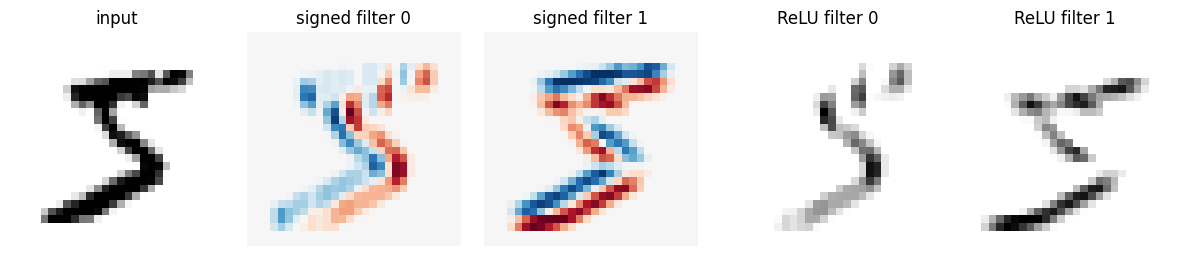

In [2]:
import torch.nn.functional as F
image = torch.from_numpy(X_train[0].reshape(1, 1, 28, 28))
kernels = torch.tensor([[[1., 0, -1], [1, 0, -1], [1, 0, -1]],
                        [[1., 1, 1], [0, 0, 0], [-1, -1, -1]]]).unsqueeze(1)
responses = F.conv2d(image, kernels, padding=1)
fig, axes = plt.subplots(1, 5, figsize=(12, 2.5))
axes[0].imshow(image[0, 0], cmap='gray_r'); axes[0].set_title('input')
for j in range(2):
    limit = responses[0, j].abs().max().item()
    axes[1+j].imshow(responses[0, j], cmap='RdBu_r', vmin=-limit, vmax=limit)
    axes[1+j].set_title(f'signed filter {j}')
    axes[3+j].imshow(responses[0, j].relu(), cmap='gray_r')
    axes[3+j].set_title(f'ReLU filter {j}')
for ax in axes: ax.axis('off')
plt.tight_layout(); plt.show()

## 3. Build the CNN and an MLP baseline

Take 6,000 images for training and a separate 2,000 for validation from the
official training split. The remaining training images are unused in this
short experiment. Keep the 10,000 official test images for the final evaluation.
Both models see the same pixels, minibatch order, and number of updates.

The **LeNet-style CNN** alternates $5\times5$ convolutions with average pooling,
then uses dense layers of widths 120 and 84 to produce ten logits. This follows
the feature-extraction and downsampling pattern in the lecture. Our variant
uses ReLU and fully connected convolutional channels; historical LeNet-5 used
different nonlinearities, partial channel connections, and a different output layer.

The **MLP baseline** is the $784\to256\to128\to10$ network from Lecture 11.
Flattening gives each dense unit access to every pixel. The CNN instead builds
features from local patches with shared weights. Predict how this changes the
number of parameters before reading the printout.

In [3]:
from torch.utils.data import TensorDataset, DataLoader
N_TRAIN, N_VALID, EPOCHS, BATCH_SIZE = 6000, 2000, 3, 128
order = np.random.default_rng(SEED).permutation(len(X_train))
train_ids, valid_ids = order[:N_TRAIN], order[N_TRAIN:N_TRAIN+N_VALID]
def dataset(X, y):
    return TensorDataset(torch.from_numpy(X.reshape(-1, 1, 28, 28)), torch.from_numpy(y))
train_set = dataset(X_train[train_ids], y_train[train_ids])
valid_loader = DataLoader(dataset(X_train[valid_ids], y_train[valid_ids]), batch_size=256)
test_loader = DataLoader(dataset(X_test, y_test), batch_size=256)
class LeNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(nn.Conv2d(1, 6, 5), nn.ReLU(), nn.AvgPool2d(2),
                                      nn.Conv2d(6, 16, 5), nn.ReLU(), nn.AvgPool2d(2))
        self.classifier = nn.Sequential(nn.Flatten(), nn.Linear(256, 120), nn.ReLU(),
                                       nn.Linear(120, 84), nn.ReLU(), nn.Linear(84, 10))
    def forward(self, x):
        return self.classifier(self.features(x))
def make_mlp():
    return nn.Sequential(nn.Flatten(), nn.Linear(784, 256), nn.ReLU(),
                         nn.Linear(256, 128), nn.ReLU(), nn.Linear(128, 10))
probe = LeNet()
z = image
for layer in [*probe.features, *probe.classifier]:
    z = layer(z)
    print(type(layer).__name__, tuple(z.shape))
assert z.shape == (1, 10)
print('LeNet parameters:', sum(p.numel() for p in probe.parameters()))
print('MLP parameters:', sum(p.numel() for p in make_mlp().parameters()))

Conv2d (1, 6, 24, 24)
ReLU (1, 6, 24, 24)
AvgPool2d (1, 6, 12, 12)
Conv2d (1, 16, 8, 8)
ReLU (1, 16, 8, 8)
AvgPool2d (1, 16, 4, 4)
Flatten (1, 256)
Linear (1, 120)
ReLU (1, 120)
Linear (1, 84)
ReLU (1, 84)
Linear (1, 10)
LeNet parameters: 44426
MLP parameters: 235146


### Follow the tensor through each layer

An image batch has shape $N\times C\times H\times W$: $N$ is the minibatch size,
$C$ is the number of channels, and $H$, $W$ are height and width.
MNIST has $C=1$. We use $N=128$ for full training minibatches; the last batch can be smaller.
Convolution mixes input channels and produces one output channel per filter.
For an input height $H$, kernel size $k$, padding $p$, stride $s$, and
dilation $d$, the output height is
$$H_{\mathrm{out}}=\left\lfloor\frac{H+2p-d(k-1)-1}{s}\right\rfloor+1.$$
The width follows the same formula. Here the convolutions have $p=0$, $s=1$,
and $d=1$, so the first gives $28-5+1=24$.
The batch dimension $N$ is preserved throughout both networks.

### LeNet-style model ($28\times 28$ MNIST input)

| Operation | Output tensor | Explanation |
|---|---|---|
| Input | $N\times 1\times 28\times 28$ | one grayscale channel |
| Conv $5\times 5$, $1\to 6$, stride 1, no padding; ReLU | $N\times 6\times 24\times 24$ | six learned filters |
| Average pool $2\times 2$, stride 2 | $N\times 6\times 12\times 12$ | channel count unchanged |
| Conv $5\times 5$, $6\to 16$; ReLU | $N\times 16\times 8\times 8$ | each filter uses all six input channels |
| Average pool $2\times 2$ | $N\times 16\times 4\times 4$ | downsample again |
| Flatten | $N\times 256$ | $16\cdot4\cdot4=256$ features per image |
| Linear $256\to 120$; ReLU | $N\times 120$ | dense hidden layer |
| Linear $120\to 84$; ReLU | $N\times 84$ | dense hidden layer |
| Linear $84\to 10$ | $N\times 10$ | ten class logits per image |

### Lecture 11 MLP baseline

| Operation | Output tensor |
|---|---|
| Same image batch | $N\times 1\times 28\times 28$ |
| Flatten | $N\times 784$ |
| Linear $784\to 256$; ReLU | $N\times 256$ |
| Linear $256\to 128$; ReLU | $N\times 128$ |
| Linear $128\to 10$ | $N\times 10$ |

Targets have shape $(N,)$ and integer values 0–9. Each row of the $N\times10$
logit matrix belongs to one image. Cross-entropy reduces these logits and their
labels to a scalar mean loss. The first trace used $N=1$; the next checks $N=4$.

In [4]:
for name, net in [('LeNet-style', LeNet()), ('MLP', make_mlp())]:
    z = torch.zeros(4, 1, 28, 28)
    print(name, 'input', tuple(z.shape))
    layers = [*net.features, *net.classifier] if isinstance(net, LeNet) else list(net)
    with torch.no_grad():
        for layer in layers:
            z = layer(z)
            print(f'  {type(layer).__name__:14s}', tuple(z.shape))
    assert z.shape == (4, 10)


LeNet-style input (4, 1, 28, 28)
  Conv2d         (4, 6, 24, 24)
  ReLU           (4, 6, 24, 24)
  AvgPool2d      (4, 6, 12, 12)
  Conv2d         (4, 16, 8, 8)
  ReLU           (4, 16, 8, 8)
  AvgPool2d      (4, 16, 4, 4)
  Flatten        (4, 256)
  Linear         (4, 120)
  ReLU           (4, 120)
  Linear         (4, 84)
  ReLU           (4, 84)
  Linear         (4, 10)
MLP input (4, 1, 28, 28)
  Flatten        (4, 784)
  Linear         (4, 256)
  ReLU           (4, 256)
  Linear         (4, 128)
  ReLU           (4, 128)
  Linear         (4, 10)


## 4. Train and watch validation loss

Training follows the Lecture 12 loop: forward pass, loss, `zero_grad`,
`backward`, and optimizer step. For minibatch $\mathcal B$, the loss is
$$L_{\mathcal B}(\theta)=-\frac{1}{|\mathcal B|}
\sum_{i\in\mathcal B}\log\frac{\exp s_{i,y_i}}
{\sum_{c=0}^{9}\exp s_{i,c}},$$
where $s_{i,c}$ is the logit for class $c$. `CrossEntropyLoss` computes this
from the logits using a numerically stable implementation.

We use Adam with learning rate $10^{-3}$ for three epochs. With 6,000 images
and minibatch size 128, each epoch has $\lceil6000/128\rceil=47$ updates.
The loader seed restarts for each model, giving them the same minibatch order.

Call `train()` while fitting and `eval()` for validation; `no_grad()` avoids
recording a backward graph during evaluation. The CNN's shared filters use
ordinary backpropagation: their gradients add contributions from all spatial
locations where each filter was applied, as in the lecture.

Watch both validation curves. Which model reduces the loss faster at these
settings, and how much progress remains at the third epoch?

{'model': 'MLP', 'epoch': 1, 'train_loss': 1.1742209652264912, 'valid_loss': 0.4432534241676331, 'valid_accuracy': 0.879, 'elapsed_seconds': 0.10278779100917745}
{'model': 'MLP', 'epoch': 2, 'train_loss': 0.383045970360438, 'valid_loss': 0.31356732511520385, 'valid_accuracy': 0.921, 'elapsed_seconds': 0.17767370800720528}
{'model': 'MLP', 'epoch': 3, 'train_loss': 0.2858579046726227, 'valid_loss': 0.28505527091026306, 'valid_accuracy': 0.9205, 'elapsed_seconds': 0.2613861250138143}


{'model': 'LeNet-style', 'epoch': 1, 'train_loss': 1.8464647919336954, 'valid_loss': 0.882401885509491, 'valid_accuracy': 0.7085, 'elapsed_seconds': 0.6493902910006}


{'model': 'LeNet-style', 'epoch': 2, 'train_loss': 0.6870610508918762, 'valid_loss': 0.5568242406845093, 'valid_accuracy': 0.838, 'elapsed_seconds': 1.2260727079992648}


{'model': 'LeNet-style', 'epoch': 3, 'train_loss': 0.5015992841720581, 'valid_loss': 0.4245479347705841, 'valid_accuracy': 0.873, 'elapsed_seconds': 1.8278098330047214}


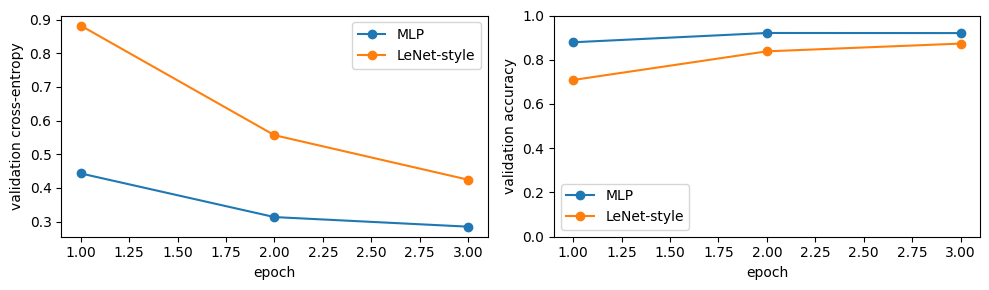

In [5]:
loss_fn = nn.CrossEntropyLoss()
@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    total_loss = correct = total = 0
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        logits = model(xb)
        total_loss += loss_fn(logits, yb).item() * len(yb)
        correct += (logits.argmax(1) == yb).sum().item()
        total += len(yb)
    return total_loss / total, correct / total
models, records = {}, []
for name, factory in [('MLP', make_mlp), ('LeNet-style', LeNet)]:
    torch.manual_seed(SEED)
    model = factory().to(device)
    loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True,
                        generator=torch.Generator().manual_seed(SEED))
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    started = time.perf_counter()
    for epoch in range(1, EPOCHS + 1):
        model.train()
        loss_sum = 0
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad(set_to_none=True)
            loss = loss_fn(model(xb), yb)
            loss.backward()
            optimizer.step()
            loss_sum += loss.item() * len(yb)
        val_loss, val_acc = evaluate(model, valid_loader)
        row = dict(model=name, epoch=epoch, train_loss=loss_sum/len(train_set),
                   valid_loss=val_loss, valid_accuracy=val_acc,
                   elapsed_seconds=time.perf_counter()-started)
        records.append(row)
        print(row)
    models[name] = model
history = pd.DataFrame(records)
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
for name, group in history.groupby('model', sort=False):
    axes[0].plot(group.epoch, group.valid_loss, 'o-', label=name)
    axes[1].plot(group.epoch, group.valid_accuracy, 'o-', label=name)
axes[0].set(xlabel='epoch', ylabel='validation cross-entropy')
axes[1].set(xlabel='epoch', ylabel='validation accuracy', ylim=(0, 1))
for ax in axes: ax.legend()
plt.tight_layout(); plt.show()

## 5. Test accuracy, learned features, and mistakes

The saved run gives the MLP higher validation accuracy after three epochs,
while the CNN uses 44,426 parameters compared with the MLP's 235,146. The CNN's
validation loss is still falling. This comparison describes a short run at one
learning rate; changing the training budget or tuning each model can change
the result.

Now evaluate both fitted models on the official test set. The table reports
mean cross-entropy and accuracy. We then pass the same digit from Section 2
through the CNN's learned first-layer filters and ReLU. Compare these six
feature maps with the fixed edge responses. Each map has its own display
scale, so read the spatial pattern within each panel.

Finally, inspect mistakes among the first 256 test images. Where does the
predicted digit resemble the true digit?

,model,test_loss,test_accuracy,parameters
0,MLP,0.292943,0.9141,235146
1,LeNet-style,0.416759,0.8743,44426


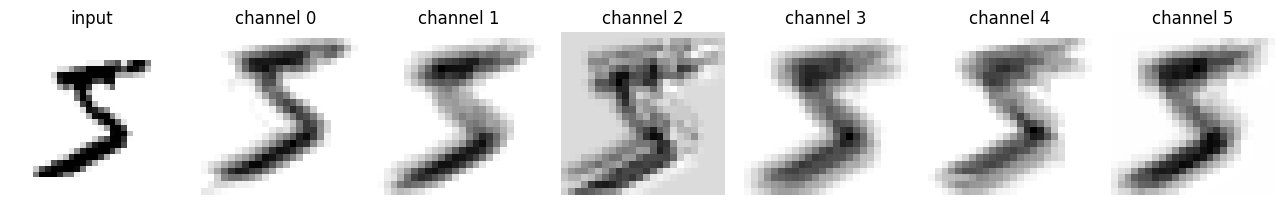

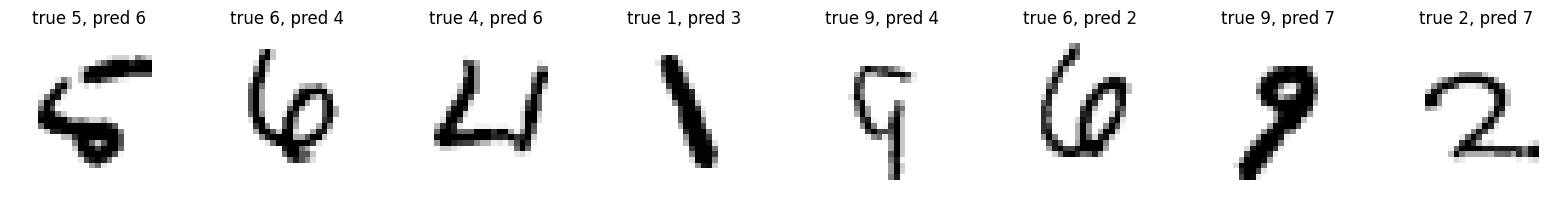

In [6]:
display(pd.DataFrame([dict(model=name, test_loss=result[0], test_accuracy=result[1],
                           parameters=sum(p.numel() for p in model.parameters()))
                      for name, model in models.items()
                      for result in [evaluate(model, test_loader)]]))
cnn = models['LeNet-style'].eval()
with torch.no_grad():
    maps = cnn.features[:2](image.to(device)).cpu()
    logits = cnn(torch.from_numpy(X_test[:256].reshape(-1, 1, 28, 28)).to(device)).cpu()
fig, axes = plt.subplots(1, 7, figsize=(13, 2))
axes[0].imshow(image[0, 0], cmap='gray_r'); axes[0].set_title('input')
for j in range(6):
    axes[j+1].imshow(maps[0, j], cmap='gray_r'); axes[j+1].set_title(f'channel {j}')
for ax in axes: ax.axis('off')
plt.tight_layout(); plt.show()
pred = logits.argmax(1).numpy()
wrong = np.flatnonzero(pred != y_test[:256])[:8]
if len(wrong):
    fig, axes = plt.subplots(1, len(wrong), figsize=(2*len(wrong), 2), squeeze=False)
    for ax, i in zip(axes[0], wrong):
        ax.imshow(X_test[i].reshape(28,28), cmap='gray_r')
        ax.set_title(f'true {y_test[i]}, pred {pred[i]}'); ax.axis('off')
    plt.tight_layout(); plt.show()
else:
    print('No mistakes in the first 256 test examples.')

## 6. Experiments to try

Change one setting at a time and compare validation results. Use the test set
after choosing the settings you want to report.

1. **Pooling.** Replace average pooling with max pooling. The tensor sizes stay
   the same; how do the feature maps and validation curves change?
2. **Training budget.** Raise `EPOCHS` to 10, keeping the split fixed. Does the
   CNN close the gap? Then increase `N_TRAIN` to 20000 and rebuild the loaders.
3. **Activation.** Replace ReLU with Tanh. How does this affect optimization?
   Which part of the model now resembles historical LeNet more closely?
4. **Locality.** Apply the same random permutation of the 784 pixel positions
   to every training, validation, and test image, then reshape to $28\times28$.
   The pixel values still contain the same information. Why does their new
   arrangement change the CNN's useful inductive bias?

### Sources

- Ben Trevett, [*PyTorch Image Classification*](https://github.com/bentrevett/pytorch-image-classification),
  especially `2_lenet.ipynb`: architecture progression and filter inspection.
  Copyright © 2018 Ben Trevett, MIT license; see `LICENSE-bentrevett`.
- SDS365 spring 2026, `convolve_demo.ipynb` and `cnn_mnist_demo.ipynb`:
  fixed-filter examples and the MNIST classification sequence.
- SDS265 Lecture 11, `mlp-training.ipynb`: MNIST loader and MLP baseline;
  Lectures 12–13: training loop, shared filters, pooling, and tensor conventions.

The code and explanations here are written for SDS265. The accompanying
[README](README.md) records the upstream revision and the changes for this lesson.